# Plate Detector Training

Trains one licence plate detector per run and publishes its weights as a private dataset (`plate-detector-<experiment>`). Models are compared in `03_evaluate_plate_detectors.ipynb`.

| Experiment | Model | Training data | Purpose |
|---|---|---|---|
| `yolo26n` | YOLO26n | Merged dataset | CityPulse detector |
| `yolo26s` | YOLO26s | Merged dataset | CityPulse detector (larger) |
| `yolov8m-paper` | YOLOv8m | Hossain localization only, original splits | Paper baseline |
| `yolov8m-paper-2stage` | YOLOv8m | Hossain localization only, original splits | Paper multi-stage method |

**Setup (Kaggle notebook)**
1. Add `bangla-plate-detection` and `bangla-licence-plates` as inputs.

In [1]:
%pip install -q ultralytics==8.4.46

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 17.9 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


## Configuration

In [2]:
EXPERIMENT = "yolov8m-paper"

EXPERIMENTS = {
    "yolo26n": {"model": "yolo26n.pt", "data": "merged", "epochs": 100, "batch": 32},
    "yolo26s": {"model": "yolo26s.pt", "data": "merged", "epochs": 100, "batch": 32},
    "yolov8m-paper": {"model": "yolov8m.pt", "data": "paper", "epochs": 80, "batch": 10},
    "yolov8m-paper-2stage": {"model": "yolov8m.pt", "data": "paper", "epochs": 80, "batch": 10, "two_stage": True},
}
IMGSZ = 640
PATIENCE = 20
SEED = 0

## Setup

In [3]:
import json
import shutil
import subprocess
import xml.etree.ElementTree as ET
from pathlib import Path

import pandas as pd
import torch
from PIL import Image
from ultralytics import YOLO

config = EXPERIMENTS[EXPERIMENT]
WORK = Path("/kaggle/working")
INPUT = Path("/kaggle/input")
RUNS = WORK / "runs"

gpus = torch.cuda.device_count()
DEVICE = ",".join(str(i) for i in range(gpus)) if gpus else "cpu"


def find_input(name: str) -> Path:
    return next(p for p in INPUT.rglob(name) if p.is_dir())


print(f"Experiment: {EXPERIMENT}  {config}\nDevice: {DEVICE}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Experiment: yolov8m-paper  {'model': 'yolov8m.pt', 'data': 'paper', 'epochs': 80, 'batch': 10}
Device: 0,1


## Prepare data

- **merged**: `bangla-plate-detection` (all sources, duplicates removed).
- **paper**: the Hossain localization set converted to YOLO with its original splits (5,687 / 277 / 553), as used in the paper.

In [4]:
def build_paper_dataset(target: Path) -> Path:
    source = find_input("bangla-licence-plates") / "bd-lpr" / "License Plate Localization"
    for src_split, split in {"train": "train", "validation": "val", "test": "test"}.items():
        (target / "images" / split).mkdir(parents=True, exist_ok=True)
        (target / "labels" / split).mkdir(parents=True, exist_ok=True)
        for image in (source / src_split).glob("*.jpg"):
            root = ET.parse(image.with_suffix(".xml")).getroot()
            width, height = Image.open(image).size
            lines = []
            for obj in root.iter("object"):
                b = obj.find("bndbox")
                x1, y1, x2, y2 = (float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))
                x1, x2, y1, y2 = max(0, x1), min(width, x2), max(0, y1), min(height, y2)
                if x2 > x1 and y2 > y1:
                    lines.append(f"0 {(x1 + x2) / 2 / width:.6f} {(y1 + y2) / 2 / height:.6f} "
                                 f"{(x2 - x1) / width:.6f} {(y2 - y1) / height:.6f}")
            shutil.copy2(image, target / "images" / split / f"bd-lpr__{image.name}")
            (target / "labels" / split / f"bd-lpr__{image.stem}.txt").write_text("\n".join(lines))
    (target / "data.yaml").write_text(
        "train: images/train\nval: images/val\ntest: images/test\nnames:\n  0: license_plate\n")
    return target


if config["data"] == "merged":
    DATA = WORK / "plate-detection"
    if not DATA.exists():
        shutil.copytree(find_input("bangla-plate-detection"), DATA)
else:
    DATA = WORK / "plate-detection-paper"
    if not DATA.exists():
        build_paper_dataset(DATA)

DATA_YAML = DATA / "data.yaml"
for split in ("train", "val", "test"):
    print(f"{split:5} {len(list((DATA / 'images' / split).iterdir())):6d} images")

train   5687 images
val      277 images
test     553 images


## Train

Single-stage experiments use Ultralytics defaults. The two-stage experiment follows the paper: stage 1 (35 epochs) uses strong spatial augmentation, stage 2 (45 epochs) shifts to photometric augmentation, and the number of frozen layers decreases from 12 to 8 to 4. Learning rates are not given in the paper; stage 2 uses a learning rate ten times lower than stage 1.

In [5]:
COMMON = dict(data=str(DATA_YAML), imgsz=IMGSZ, device=DEVICE, seed=SEED, project=str(RUNS), exist_ok=True)

STAGE_1 = dict(degrees=8, translate=0.15, scale=0.7, shear=3, mosaic=1.0, mixup=0.15, copy_paste=0.4,
               fliplr=0.5, hsv_h=0.01, hsv_s=0.8, hsv_v=0.5, lr0=0.01, momentum=0.95, weight_decay=0.001)
STAGE_2 = dict(degrees=3, translate=0.08, scale=0.4, shear=1, mosaic=0.7, mixup=0.08, copy_paste=0.2,
               fliplr=0.3, hsv_h=0.02, hsv_s=0.9, hsv_v=0.7, lr0=0.001, momentum=0.9, weight_decay=0.0005)
PHASES = [  # epochs, frozen layers, augmentation
    (20, 12, STAGE_1),
    (15, 8, STAGE_1),
    (45, 4, STAGE_2),
]

if config.get("two_stage"):
    weights = config["model"]
    for i, (epochs, freeze, hyp) in enumerate(PHASES, start=1):
        YOLO(weights).train(**COMMON, **hyp, name=f"{EXPERIMENT}-phase{i}", epochs=epochs,
                            batch=config["batch"], freeze=freeze, warmup_epochs=3 if i == 1 else 0)
        weights = RUNS / f"{EXPERIMENT}-phase{i}" / "weights" / "last.pt"
    RUN = RUNS / f"{EXPERIMENT}-phase{len(PHASES)}"
else:
    YOLO(config["model"]).train(**COMMON, name=EXPERIMENT, epochs=config["epochs"],
                                batch=config["batch"], patience=PATIENCE)
    RUN = RUNS / EXPERIMENT

New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.46 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                       CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=10, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/plate-detection-paper/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_d

## Training curves

Epochs: 78  best epoch 58: mAP@0.5 0.9876  mAP@0.5:0.95 0.7539


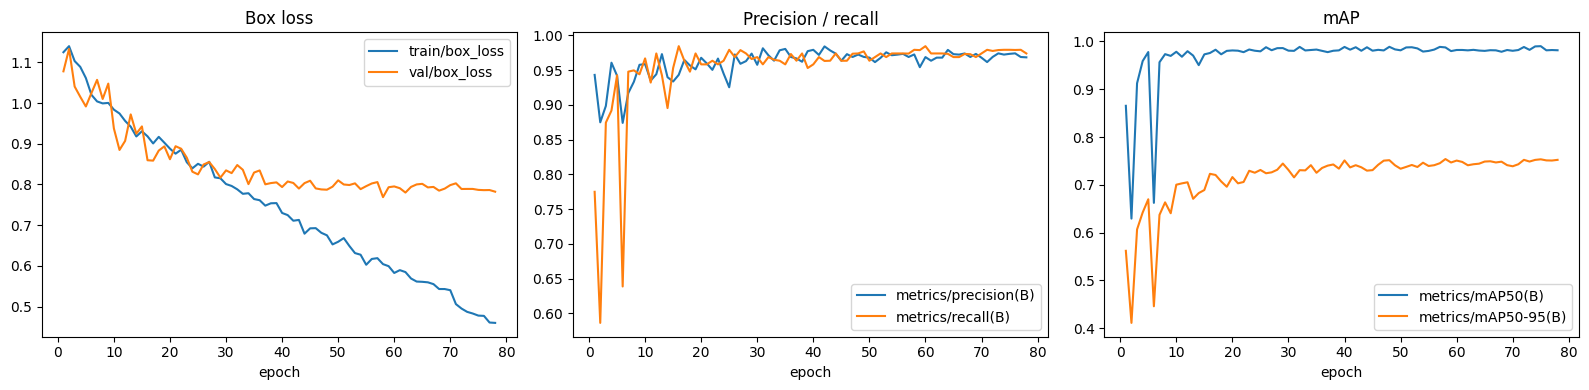

In [6]:
import matplotlib.pyplot as plt

runs = sorted(RUNS.glob(f"{EXPERIMENT}*")) if config.get("two_stage") else [RUN]
df = pd.concat([pd.read_csv(r / "results.csv") for r in runs], ignore_index=True)
df.columns = df.columns.str.strip()
df["epoch"] = range(1, len(df) + 1)
best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
print(f"Epochs: {len(df)}  best epoch {int(best['epoch'])}: "
      f"mAP@0.5 {best['metrics/mAP50(B)']:.4f}  mAP@0.5:0.95 {best['metrics/mAP50-95(B)']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for keys, ax, title in [
    (("train/box_loss", "val/box_loss"), axes[0], "Box loss"),
    (("metrics/precision(B)", "metrics/recall(B)"), axes[1], "Precision / recall"),
    (("metrics/mAP50(B)", "metrics/mAP50-95(B)"), axes[2], "mAP"),
]:
    for key in keys:
        ax.plot(df["epoch"], df[key], label=key)
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

In [2]:
EXPERIMENT = "yolov8m-paper-2stage"

EXPERIMENTS = {
    "yolo26n": {"model": "yolo26n.pt", "data": "merged", "epochs": 100, "batch": 32},
    "yolo26s": {"model": "yolo26s.pt", "data": "merged", "epochs": 100, "batch": 32},
    "yolov8m-paper": {"model": "yolov8m.pt", "data": "paper", "epochs": 80, "batch": 10},
    "yolov8m-paper-2stage": {"model": "yolov8m.pt", "data": "paper", "epochs": 80, "batch": 10, "two_stage": True},
}
IMGSZ = 640
PATIENCE = 20
SEED = 0

In [3]:
import json
import shutil
import subprocess
import xml.etree.ElementTree as ET
from pathlib import Path

import pandas as pd
import torch
from PIL import Image
from ultralytics import YOLO

config = EXPERIMENTS[EXPERIMENT]
WORK = Path("/kaggle/working")
INPUT = Path("/kaggle/input")
RUNS = WORK / "runs"

gpus = torch.cuda.device_count()
DEVICE = ",".join(str(i) for i in range(gpus)) if gpus else "cpu"


def find_input(name: str) -> Path:
    return next(p for p in INPUT.rglob(name) if p.is_dir())


print(f"Experiment: {EXPERIMENT}  {config}\nDevice: {DEVICE}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Experiment: yolov8m-paper-2stage  {'model': 'yolov8m.pt', 'data': 'paper', 'epochs': 80, 'batch': 10, 'two_stage': True}
Device: 0,1


In [4]:
def build_paper_dataset(target: Path) -> Path:
    source = find_input("bangla-licence-plates") / "bd-lpr" / "License Plate Localization"
    for src_split, split in {"train": "train", "validation": "val", "test": "test"}.items():
        (target / "images" / split).mkdir(parents=True, exist_ok=True)
        (target / "labels" / split).mkdir(parents=True, exist_ok=True)
        for image in (source / src_split).glob("*.jpg"):
            root = ET.parse(image.with_suffix(".xml")).getroot()
            width, height = Image.open(image).size
            lines = []
            for obj in root.iter("object"):
                b = obj.find("bndbox")
                x1, y1, x2, y2 = (float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))
                x1, x2, y1, y2 = max(0, x1), min(width, x2), max(0, y1), min(height, y2)
                if x2 > x1 and y2 > y1:
                    lines.append(f"0 {(x1 + x2) / 2 / width:.6f} {(y1 + y2) / 2 / height:.6f} "
                                 f"{(x2 - x1) / width:.6f} {(y2 - y1) / height:.6f}")
            shutil.copy2(image, target / "images" / split / f"bd-lpr__{image.name}")
            (target / "labels" / split / f"bd-lpr__{image.stem}.txt").write_text("\n".join(lines))
    (target / "data.yaml").write_text(
        "train: images/train\nval: images/val\ntest: images/test\nnames:\n  0: license_plate\n")
    return target


if config["data"] == "merged":
    DATA = WORK / "plate-detection"
    if not DATA.exists():
        shutil.copytree(find_input("bangla-plate-detection"), DATA)
else:
    DATA = WORK / "plate-detection-paper"
    if not DATA.exists():
        build_paper_dataset(DATA)

DATA_YAML = DATA / "data.yaml"
for split in ("train", "val", "test"):
    print(f"{split:5} {len(list((DATA / 'images' / split).iterdir())):6d} images")

train   5687 images
val      277 images
test     553 images


In [5]:
COMMON = dict(data=str(DATA_YAML), imgsz=IMGSZ, device=DEVICE, seed=SEED, project=str(RUNS), exist_ok=True)

STAGE_1 = dict(degrees=8, translate=0.15, scale=0.7, shear=3, mosaic=1.0, mixup=0.15, copy_paste=0.4,
               fliplr=0.5, hsv_h=0.01, hsv_s=0.8, hsv_v=0.5, lr0=0.01, momentum=0.95, weight_decay=0.001)
STAGE_2 = dict(degrees=3, translate=0.08, scale=0.4, shear=1, mosaic=0.7, mixup=0.08, copy_paste=0.2,
               fliplr=0.3, hsv_h=0.02, hsv_s=0.9, hsv_v=0.7, lr0=0.001, momentum=0.9, weight_decay=0.0005)
PHASES = [  # epochs, frozen layers, augmentation
    (20, 12, STAGE_1),
    (15, 8, STAGE_1),
    (45, 4, STAGE_2),
]

if config.get("two_stage"):
    weights = config["model"]
    for i, (epochs, freeze, hyp) in enumerate(PHASES, start=1):
        YOLO(weights).train(**COMMON, **hyp, name=f"{EXPERIMENT}-phase{i}", epochs=epochs,
                            batch=config["batch"], freeze=freeze, warmup_epochs=3 if i == 1 else 0)
        weights = RUNS / f"{EXPERIMENT}-phase{i}" / "weights" / "last.pt"
    RUN = RUNS / f"{EXPERIMENT}-phase{len(PHASES)}"
else:
    YOLO(config["model"]).train(**COMMON, name=EXPERIMENT, epochs=config["epochs"],
                                batch=config["batch"], patience=PATIENCE)
    RUN = RUNS / EXPERIMENT

New https://pypi.org/project/ultralytics/8.4.176 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.46 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                       CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=10, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.4, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/plate-detection-paper/data.yaml, degrees=8, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=12, half=False, hsv_h=0.01, hsv_s=0.8, hsv_v=0.5, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=30

Epochs: 80  best epoch 65: mAP@0.5 0.9861  mAP@0.5:0.95 0.7412


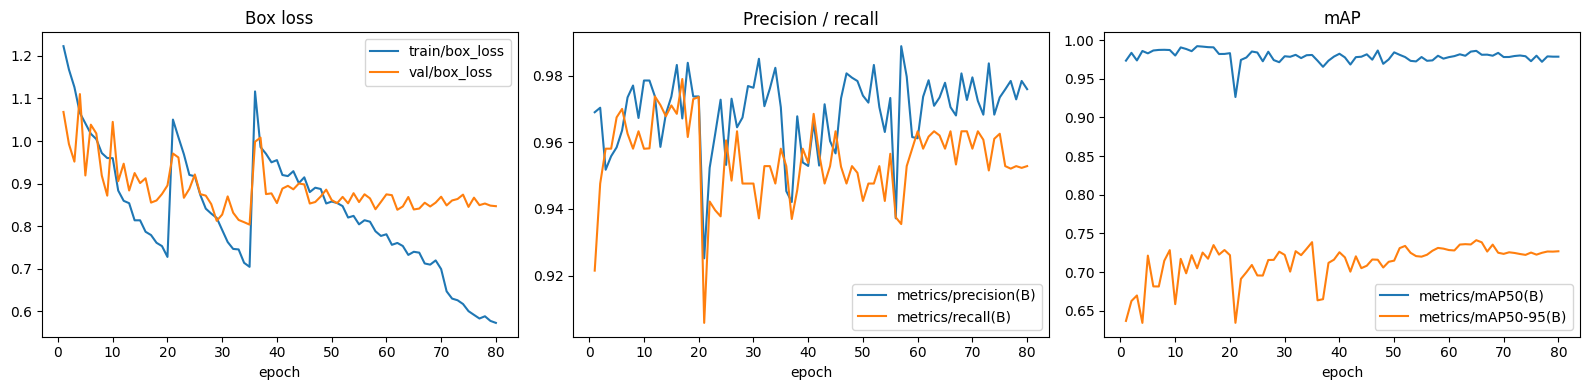

In [6]:
import matplotlib.pyplot as plt

runs = sorted(RUNS.glob(f"{EXPERIMENT}*")) if config.get("two_stage") else [RUN]
df = pd.concat([pd.read_csv(r / "results.csv") for r in runs], ignore_index=True)
df.columns = df.columns.str.strip()
df["epoch"] = range(1, len(df) + 1)
best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
print(f"Epochs: {len(df)}  best epoch {int(best['epoch'])}: "
      f"mAP@0.5 {best['metrics/mAP50(B)']:.4f}  mAP@0.5:0.95 {best['metrics/mAP50-95(B)']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for keys, ax, title in [
    (("train/box_loss", "val/box_loss"), axes[0], "Box loss"),
    (("metrics/precision(B)", "metrics/recall(B)"), axes[1], "Precision / recall"),
    (("metrics/mAP50(B)", "metrics/mAP50-95(B)"), axes[2], "mAP"),
]:
    for key in keys:
        ax.plot(df["epoch"], df[key], label=key)
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()